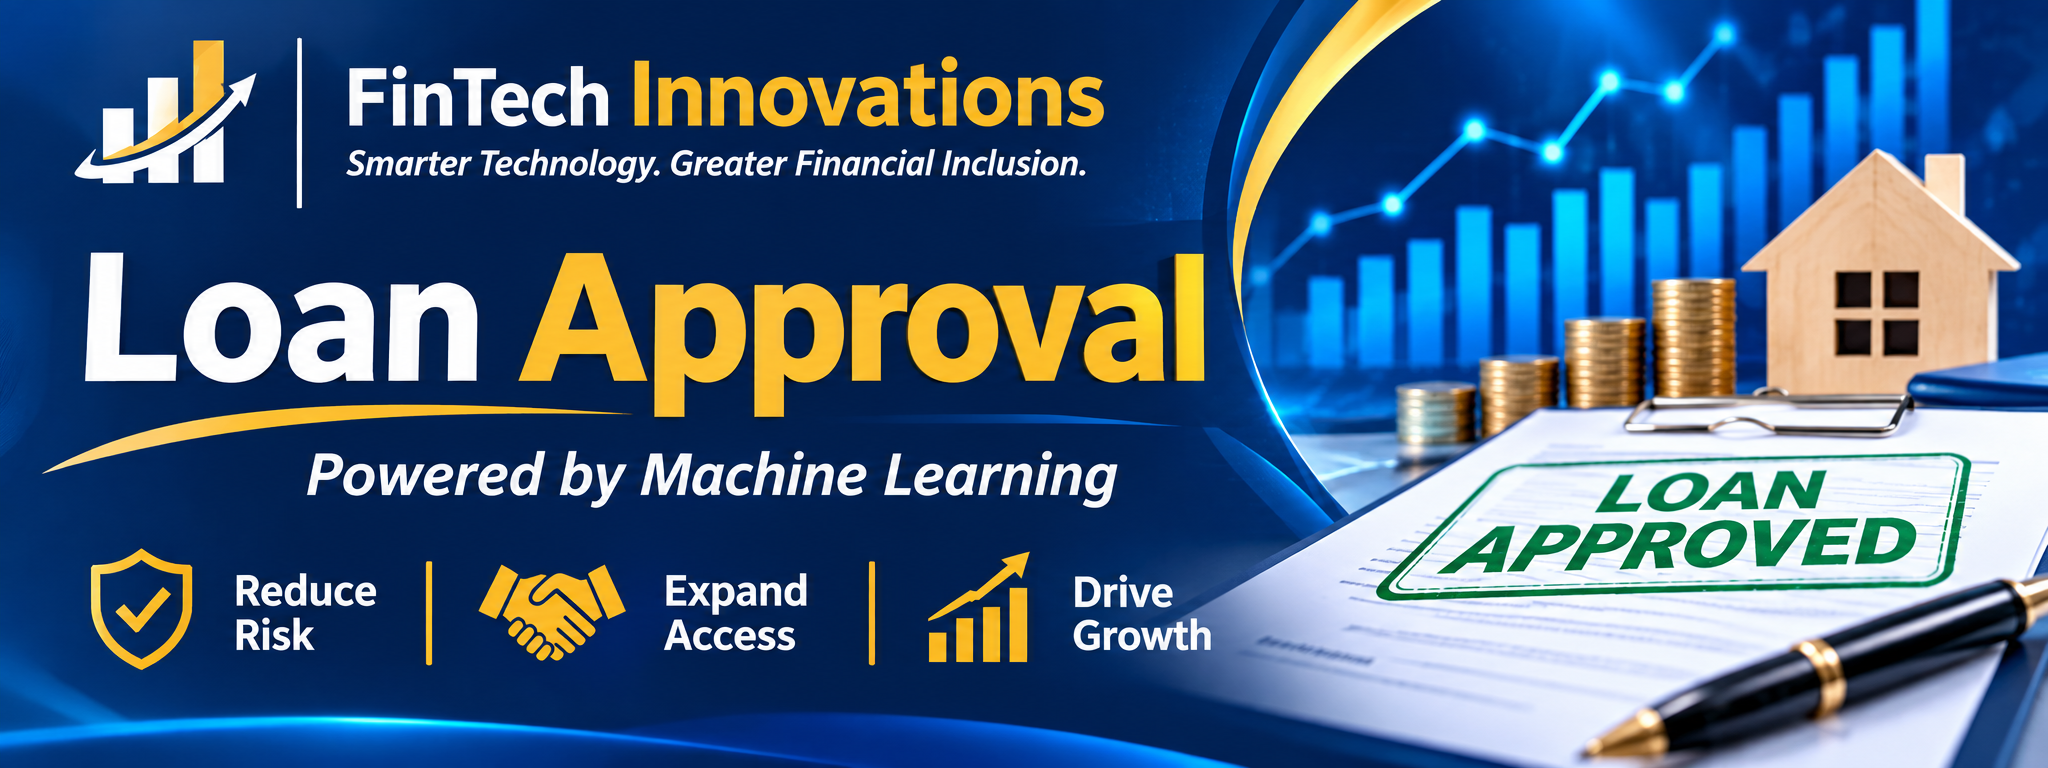

In [ ]:
from IPython.display import Image, display

display(Image(filename='/Loan Approval Banner.png',
              width=1200))

# Machine Learning for Smarter Loan Approval Decisions

### Predicting Credit Risk, Improving Lending Decisions, and Minimizing Financial Losses

**Company:** FinTech Innovations

## Overview

### BLUF (Bottom Line Up Front)

The Logistic Regression model emerged as the best-performing model for predicting historical loan approval decisions, achieving **93.35% accuracy, 85.88% F1-score, 97.99% ROC-AUC and 90.36% balanced accuracy** on the test dataset. Compared with the baseline model's 76.10% accuracy, this represents a substantial improvement in classification performance. The findings demonstrate the potential of machine learning to support faster, more consistent and data-driven loan approval decisions. However, the model predicts historical approval patterns rather than actual borrower defaults or repayment outcomes. Therefore, it should initially be used as a decision-support tool with human oversight. Further validation using actual loan repayment and default data is necessary before it can be relied upon for credit-risk assessment or financial loss reduction.

# Business Context and Problem Definition

## Business Context

FinTech Innovations currently relies on manual loan application reviews by loan officers. This process can result in delays, inconsistent approval decisions, human bias and missed opportunities to identify suitable applicants.

The company has access to 20,000 historical loan applications containing applicant financial and personal information, together with historical loan approval decisions.

This project aims to develop a machine learning classification model that predicts historical loan approval decisions. The model will help demonstrate how data-driven methods can support more consistent and efficient lending decisions.

An important limitation is that the available target variable, LoanApproved, records whether an application was approved or rejected. It does not directly indicate whether an approved borrower subsequently defaulted or successfully repaid the loan.

Therefore, the current model evaluates historical approval patterns rather than directly predicting actual borrower default risk.

## Key Stakeholders and Their Needs

- **Management:** Improved operational efficiency, informed lending decisions and reduced financial exposure.
- **Loan Officers:** Faster assessments, reliable predictions and understandable model recommendations.
- **Customers:** Fair lending decisions, faster application processing and reduced unjustified rejection.
- **Risk and Compliance Teams:** Transparent, interpretable models and responsible use of applicant information.

## Business Impact of Model Errors

The business has identified two major financial risks:

- Approving a borrower who subsequently defaults could result in an average loss of $50,000.
- Rejecting a creditworthy applicant could result in an average lost profit of $8,000.

The cost of approving a bad loan is therefore 6.25 times greater than the estimated profit lost from rejecting a good loan.

These figures are important when designing a future credit-risk model. However, the current dataset does not provide actual repayment or default outcomes. Consequently, the financial costs of these errors cannot be directly calculated using the current LoanApproved target.

## Choice of Modeling Approach

A binary classification approach is selected because the available target variable, LoanApproved, contains two possible outcomes:

- 0: Loan rejected.
- 1: Loan approved.

The objective is to predict historical loan approval decisions using applicant characteristics.

A regression approach could be considered in a future project if a continuous outcome, such as probability of default or expected financial loss, becomes available.

For this project, classification is appropriate because it aligns with the available target variable and allows comparison of different machine learning algorithms.

The model is intended to support loan officers' decisions rather than replace human judgment.

## Modeling Goals and Evaluation Metrics

The primary objective is to develop an accurate, reliable and interpretable classification model.

The following metrics will be used:

- **Accuracy:** Measures the overall proportion of correctly classified applications.
- **Precision:** Measures how many applications predicted as approved were actually approved.
- **Recall:** Measures how many historically approved applications were correctly identified.
- **F1-score:** Balances precision and recall.
- **ROC-AUC:** Measures the model's ability to distinguish between approved and rejected applications.
- **Balanced Accuracy:** Accounts for performance across both target classes.

Because the dataset is imbalanced, accuracy alone will not be sufficient to assess model performance.

The $8,000 and $50,000 business costs will be discussed as considerations for a future default-risk model rather than used as measured costs for the current approval-classification model.

## Baseline Performance Targets

The following preliminary targets will guide model development:

- ROC-AUC >= 0.80
- F1-score >= 0.80
- Balanced Accuracy >= 0.80
- Recall >= 0.80

These targets will be evaluated against the actual model results.

The final model will be selected based on predictive performance, cross-validation results, interpretability and suitability for supporting responsible lending decisions.

## Financial Cost Analysis and Business Implications

The financial implications of incorrect loan decisions are asymmetric.
Approving an applicant who subsequently defaults results in an estimated
loss of $50,000, while rejecting a creditworthy applicant results in
an estimated lost profit of $8,000.

This means that a false approval is 6.25 times more expensive than
a false denial.

For a future default prediction model where default is treated as
the positive class:

- False Positive (FP): A creditworthy applicant is incorrectly
  classified as likely to default, resulting in a potential lost
  profit of $8,000.
- False Negative (FN): An applicant who will default is incorrectly
  classified as unlikely to default, resulting in a potential loss
  of $50,000.

The estimated total business cost can therefore be expressed as:

Total Cost = (FP × $8,000) + (FN × $50,000)

### Illustrative Financial Scenario

Assuming a future default prediction model produces 10 false positives
and 5 false negatives:

- Cost of false positives = 10 × $8,000 = $80,000
- Cost of false negatives = 5 × $50,000 = $250,000
- Total estimated cost = $330,000

This example demonstrates why minimizing classification errors
without considering their financial consequences may lead to
suboptimal lending decisions.

### Limitation of the Current Dataset

The current dataset uses LoanApproved as its target variable,
representing historical approval and rejection decisions.

It does not directly identify whether borrowers subsequently
defaulted or successfully repaid their loans.

Consequently, the above financial cost framework is a proposed
evaluation approach for a future default prediction model.
It cannot be directly applied to the current approval prediction
model without actual repayment outcome data.

A future implementation should incorporate repayment history,
default status and appropriate validation data to measure the
actual financial impact of model decisions.

# 2. Data Understanding

## 2.1 Dataset Overview

The dataset contains 20,000 historical loan applications
and 35 columns representing applicant demographics,
financial information, credit history and loan characteristics.

The target variable is LoanApproved, which records
whether an application was historically approved or rejected.

The dataset contains both numerical and categorical
variables, as well as missing values in selected features.

Exploratory Data Analysis (EDA) was conducted to understand
the dataset structure, identify patterns, investigate
data quality issues and examine relationships between
applicant characteristics and historical loan approval
decisions.

The analysis includes descriptive statistics, distribution
visualizations, correlation analysis, missing value
investigation, outlier detection and statistical testing.

### 2.2 Feature Classification

The dataset contains 30 predictor variables after excluding
the target variable and features identified as potentially
affected by data leakage.

The features are categorized into three groups:

**Numerical Features**

These include applicant age, income, credit scores,
loan characteristics, financial balances, debt obligations
and credit history measurements.

**Nominal Categorical Features**

These include employment status, marital status,
home ownership status, bankruptcy history and loan purpose.
These variables represent categories without a natural order.

**Ordinal Categorical Features**

EducationLevel is treated as an ordinal feature because
its categories represent an educational progression.

PaymentHistory is stored as a numerical variable, but its
meaning and scale should be reviewed to determine whether
it represents an ordinal rating.

### Implications for Preprocessing

Numerical features require appropriate missing-value
imputation and scaling where necessary.

Nominal categorical features require encoding, such as
One-Hot Encoding, to convert categories into numerical
representations.

Ordinal features may require ordinal encoding where
their category order is clearly defined.

The selected preprocessing methods will be implemented
within a Scikit-learn ColumnTransformer and Pipeline
to ensure consistent processing during model training
and evaluation.

In [ ]:
# Imports
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.svm import SVC

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    make_scorer
)

# Statistical analysis
from scipy.stats import chi2_contingency, mannwhitneyu

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

# Visualization settings
sns.set_theme(style="whitegrid")

# Reproducibility
RANDOM_STATE = 42

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
import os

print(os.listdir())

['.config', 'financial_loan_data.csv', 'sample_data']


In [57]:
# Load the financial loan dataset
df = pd.read_csv('financial_loan_data.csv')

# Convert AnnualIncome from currency text to numeric
df['AnnualIncome'] = pd.to_numeric(
    df['AnnualIncome']
    .astype(str)
    .str.replace(r'[$,]', '', regex=True),
    errors='coerce'
)

# Display the first five rows
df.head()

,Age,AnnualIncome,CreditScore,EmploymentStatus,EducationLevel,Experience,LoanAmount,LoanDuration,MaritalStatus,NumberOfDependents,HomeOwnershipStatus,MonthlyDebtPayments,CreditCardUtilizationRate,NumberOfOpenCreditLines,NumberOfCreditInquiries,DebtToIncomeRatio,BankruptcyHistory,LoanPurpose,PreviousLoanDefaults,PaymentHistory,LengthOfCreditHistory,SavingsAccountBalance,CheckingAccountBalance,TotalAssets,TotalLiabilities,MonthlyIncome,UtilityBillsPaymentHistory,JobTenure,NetWorth,BaseInterestRate,InterestRate,MonthlyLoanPayment,TotalDebtToIncomeRatio,LoanApproved,RiskScore
0,45,39948.000,617,Employed,Master,22,13152,48,Married,2,Own,183,0.354,1,2,0.358,No,Home,0,29,9,7632.000,1202,146111,19183,3329.000,0.725,11,126928,0.200,0.228,419.806,0.181,0,49.000
1,38,39709.000,628,Employed,Associate,15,26045,48,Single,1,Mortgage,496,0.088,5,3,0.330,No,Debt Consolidation,0,21,9,4627.000,3460,53204,9595,3309.083,0.935,3,43609,0.207,0.201,794.054,0.390,0,52.000
2,47,40724.000,570,Employed,Bachelor,26,17627,36,NaN,2,Rent,902,0.137,2,0,0.245,No,Education,0,20,22,886.000,895,25176,128874,3393.667,0.872,6,5205,0.218,0.213,666.407,0.462,0,52.000
3,58,69084.000,545,Employed,High School,34,37898,96,Single,1,Mortgage,755,0.268,2,1,0.436,No,Home,0,27,10,1675.000,1217,104822,5370,5757.000,0.896,5,99452,0.300,0.301,1047.507,0.313,0,54.000
4,37,103264.000,594,Employed,Associate,17,9184,36,Married,1,Mortgage,274,0.321,0,0,0.079,No,Debt Consolidation,0,26,27,1555.000,4981,244305,17286,8605.333,0.941,5,227019,0.197,0.176,330.179,0.070,1,36.000


In [ ]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

Dataset shape: (20000, 35)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 35 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         20000 non-null  int64  
 1   AnnualIncome                20000 non-null  object 
 2   CreditScore                 20000 non-null  int64  
 3   EmploymentStatus            20000 non-null  object 
 4   EducationLevel              19099 non-null  object 
 5   Experience                  20000 non-null  int64  
 6   LoanAmount                  20000 non-null  int64  
 7   LoanDuration                20000 non-null  int64  
 8   MaritalStatus               18669 non-null  object 
 9   NumberOfDependents          20000 non-null  int64  
 10  HomeOwnershipStatus         20000 non-null  object 
 11  MonthlyDebtPayments         20000 non-null  int64  
 12  CreditCardUtilizationRate   20000 non-null  float64
 13  Numb

In [59]:
# Display numerical and categorical features

print("NUMERICAL FEATURES")
print("------------------")
for feature in numeric_features:
    print(feature)

print("\nCATEGORICAL FEATURES")
print("--------------------")
for feature in categorical_features:
    print(feature)

print("\nTOTAL FEATURES:", len(numeric_features) + len(categorical_features))

NUMERICAL FEATURES
------------------
Age
AnnualIncome
CreditScore
Experience
LoanAmount
LoanDuration
NumberOfDependents
MonthlyDebtPayments
CreditCardUtilizationRate
NumberOfOpenCreditLines
NumberOfCreditInquiries
DebtToIncomeRatio
PreviousLoanDefaults
PaymentHistory
LengthOfCreditHistory
SavingsAccountBalance
CheckingAccountBalance
TotalAssets
TotalLiabilities
MonthlyIncome
UtilityBillsPaymentHistory
JobTenure
NetWorth
TotalDebtToIncomeRatio

CATEGORICAL FEATURES
--------------------
EmploymentStatus
EducationLevel
MaritalStatus
HomeOwnershipStatus
BankruptcyHistory
LoanPurpose

TOTAL FEATURES: 30


In [ ]:
# Check missing values in each column
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

# Check for duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing Values:
EducationLevel            901
MaritalStatus            1331
SavingsAccountBalance     572
dtype: int64

Number of duplicate rows: 0


In [ ]:
# Count approved and rejected loan applications
print(df['LoanApproved'].value_counts())

# Calculate percentages
print("\nPercentage distribution:")
print(df['LoanApproved'].value_counts(normalize=True) * 100)

LoanApproved
0    15220
1     4780
Name: count, dtype: int64

Percentage distribution:
LoanApproved
0   76.100
1   23.900
Name: proportion, dtype: float64


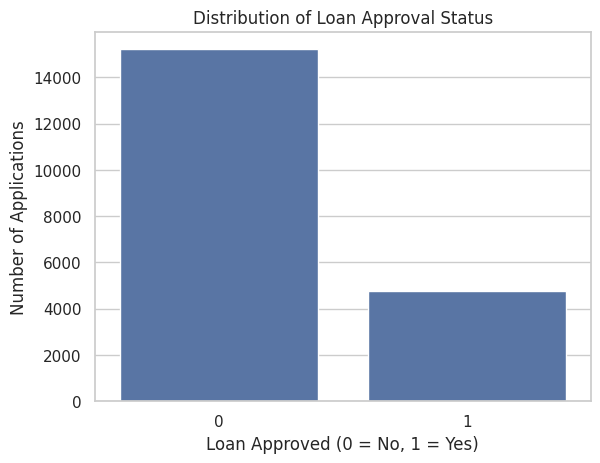

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='LoanApproved')
plt.title('Distribution of Loan Approval Status')
plt.xlabel('Loan Approved (0 = No, 1 = Yes)')
plt.ylabel('Number of Applications')
plt.show()

### Target Variable Analysis

The target variable, LoanApproved, contains two classes:
- 0: Loan not approved (15,220 applications; 76.1%).
- 1: Loan approved (4,780 applications; 23.9%).

The distribution indicates class imbalance, with rejected applications forming the majority class. Accuracy alone may therefore be misleading. Precision, recall, F1-score and ROC-AUC will also be used to evaluate model performance.

The prediction task is to classify historical loan approval decisions. Since actual loan repayment or default outcomes are unavailable, the model cannot directly predict borrower default risk.

In [ ]:
# Generate descriptive statistics for numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,20000.000,39.753,11.623,18.000,32.000,40.000,48.000,80.000
CreditScore,20000.000,571.612,50.997,343.000,540.000,578.000,609.000,712.000
Experience,20000.000,17.523,11.317,0.000,9.000,17.000,25.000,61.000
LoanAmount,20000.000,24882.868,13427.421,3674.000,15575.000,21914.500,30835.000,184732.000
LoanDuration,20000.000,54.057,24.665,12.000,36.000,48.000,72.000,120.000
NumberOfDependents,20000.000,1.517,1.386,0.000,0.000,1.000,2.000,5.000
MonthlyDebtPayments,20000.000,454.293,240.508,50.000,286.000,402.000,564.000,2919.000
CreditCardUtilizationRate,20000.000,0.286,0.160,0.001,0.161,0.267,0.391,0.917
NumberOfOpenCreditLines,20000.000,3.023,1.736,0.000,2.000,3.000,4.000,13.000
NumberOfCreditInquiries,20000.000,0.993,0.987,0.000,0.000,1.000,2.000,7.000


### Descriptive Statistics Findings

The dataset contains 20,000 loan applications with varying applicant financial and demographic characteristics.

Key findings include:
- The average applicant age is approximately 40 years.
- The average credit score is 571.61.
- The average loan amount is approximately 24,882.87.
- SavingsAccountBalance has a wide range, with a maximum of 200,089.
- TotalDebtToIncomeRatio reaches 4.648, indicating potentially high debt burdens for some applicants.
- RiskScore has an average of 50.77.

Some financial variables show substantial variation and potential extreme values. These will be investigated further using visualizations and outlier analysis. Extreme observations will not automatically be removed because they may represent genuine applicant characteristics.

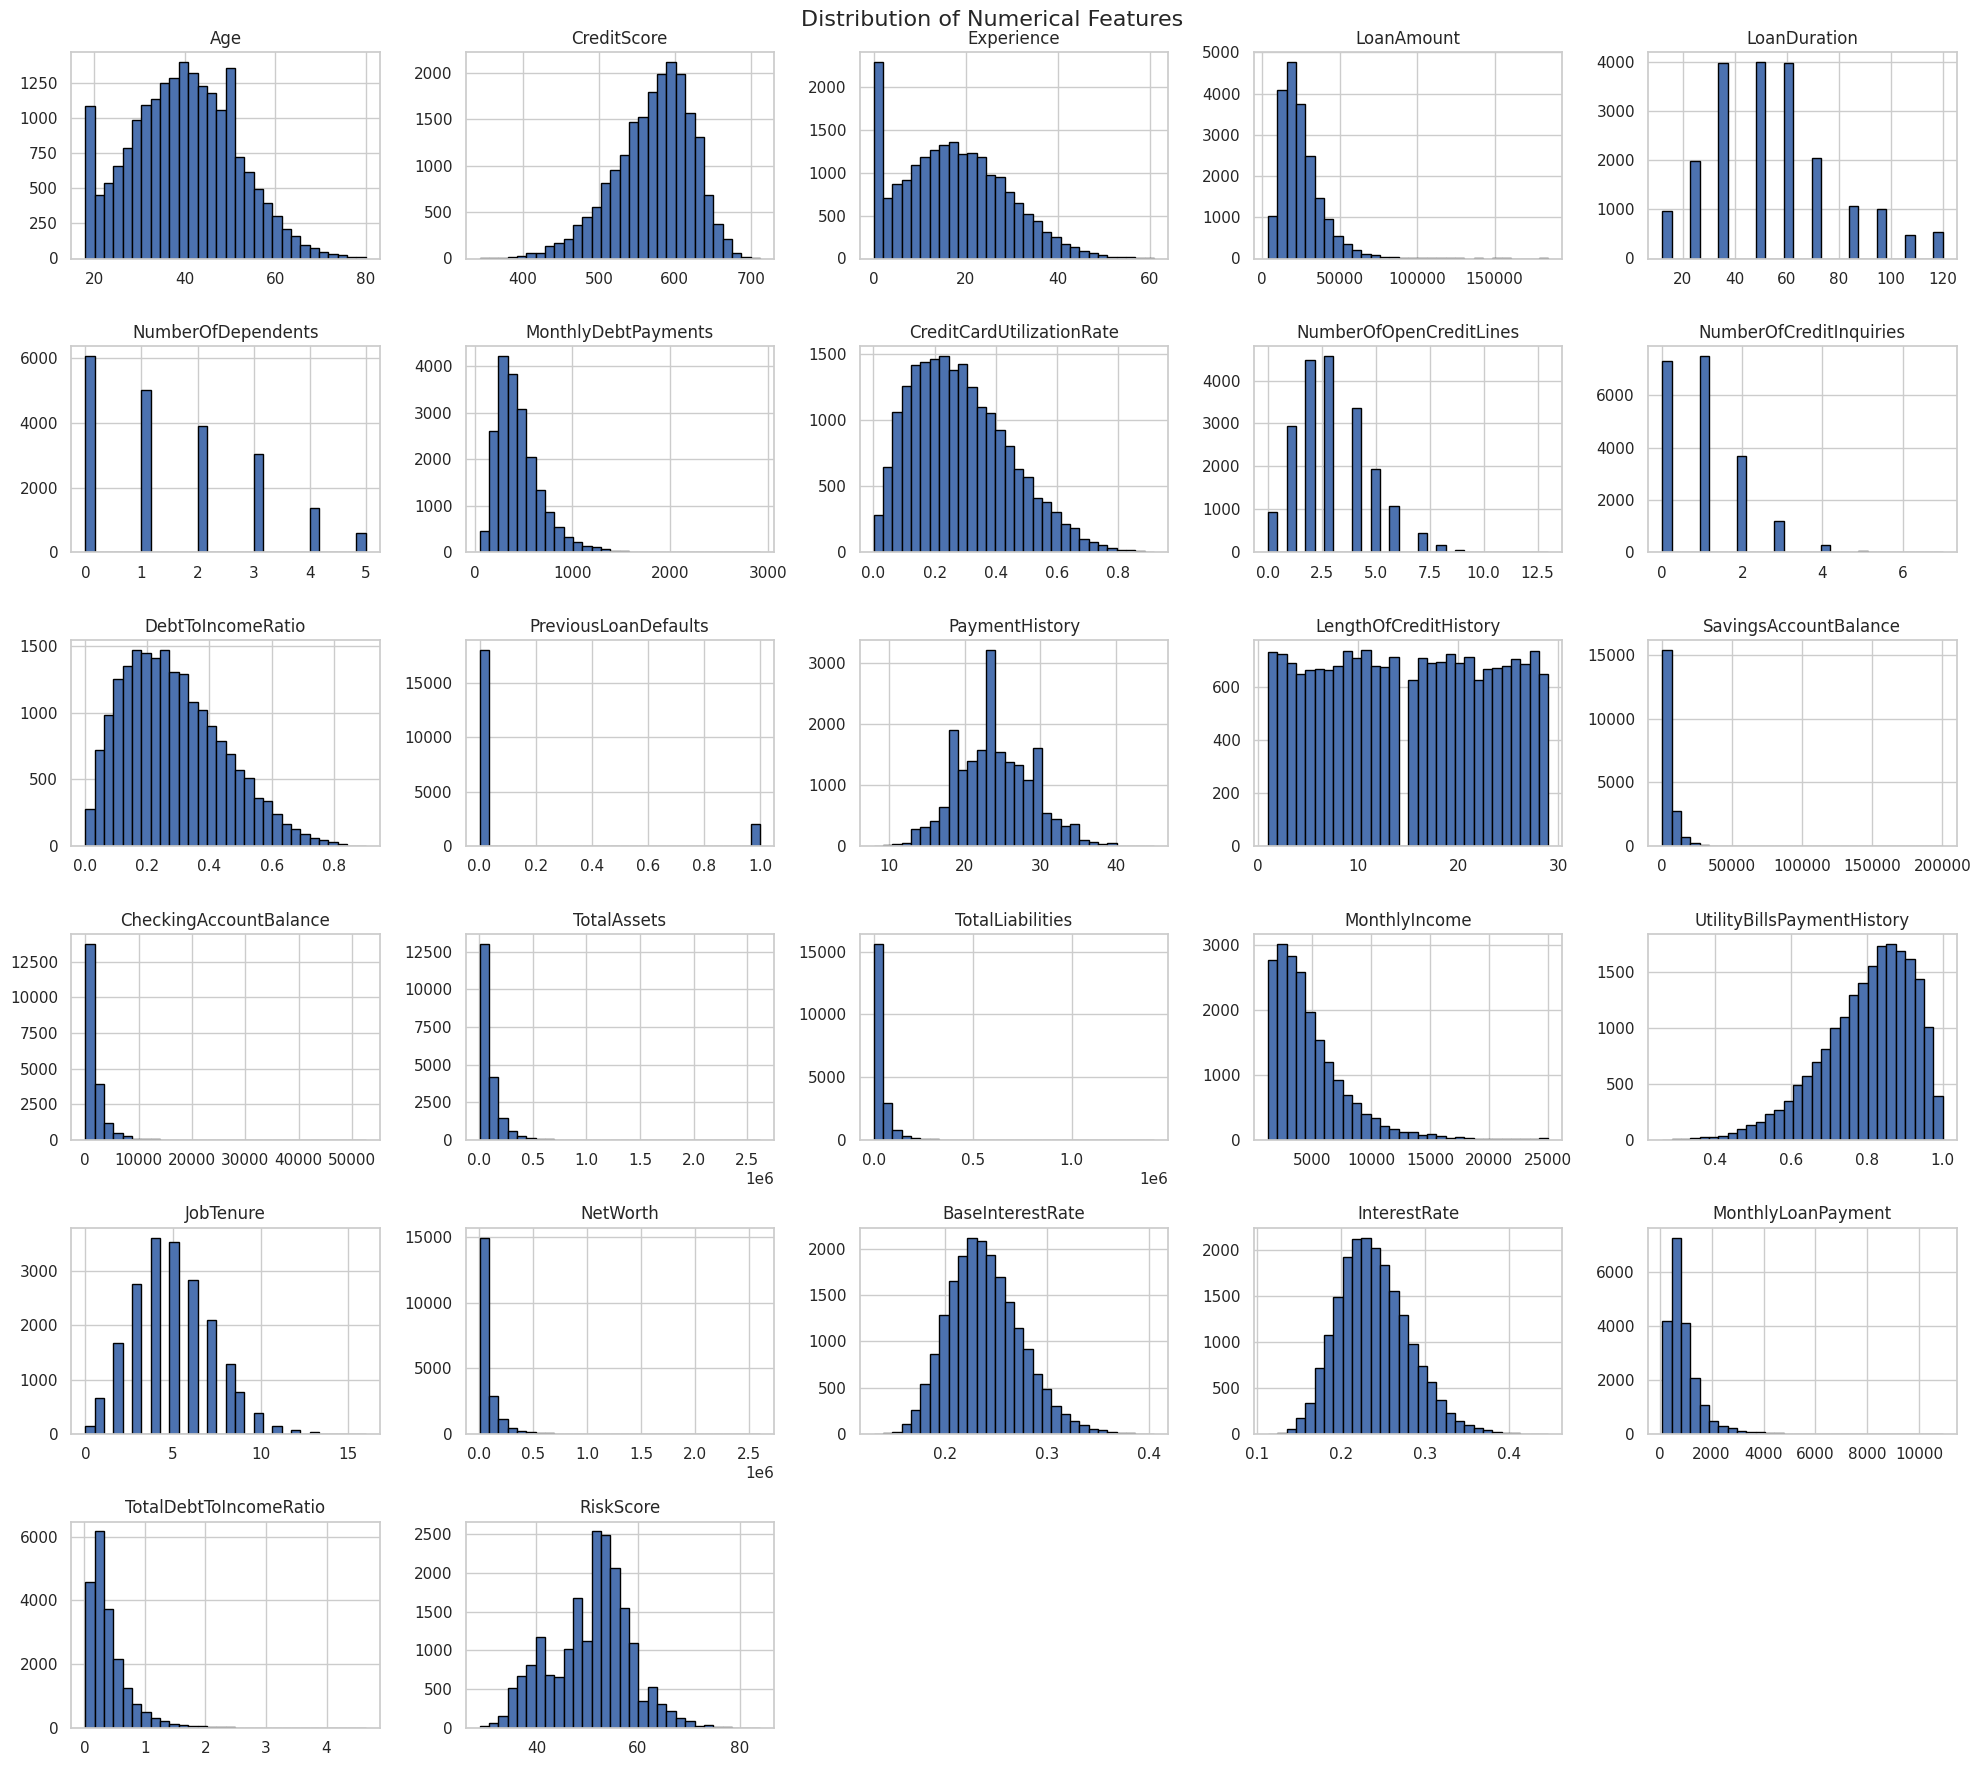

In [ ]:
# Select numerical columns, excluding the target
numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns.drop('LoanApproved')

# Plot histograms
df[numeric_columns].hist(
    figsize=(20, 18),
    bins=30,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

Correlation with Loan Approval:
LoanApproved                  1.000
MonthlyIncome                 0.604
NetWorth                      0.188
TotalAssets                   0.184
CreditScore                   0.142
Age                           0.141
Experience                    0.141
LengthOfCreditHistory         0.106
PaymentHistory                0.031
JobTenure                     0.005
UtilityBillsPaymentHistory    0.003
NumberOfDependents            0.002
CheckingAccountBalance        0.001
DebtToIncomeRatio             0.000
SavingsAccountBalance        -0.000
NumberOfOpenCreditLines      -0.005
NumberOfCreditInquiries      -0.006
CreditCardUtilizationRate    -0.010
TotalLiabilities             -0.029
PreviousLoanDefaults         -0.065
MonthlyDebtPayments          -0.070
LoanDuration                 -0.095
MonthlyLoanPayment           -0.184
LoanAmount                   -0.239
BaseInterestRate             -0.247
InterestRate                 -0.302
TotalDebtToIncomeRatio       -0.

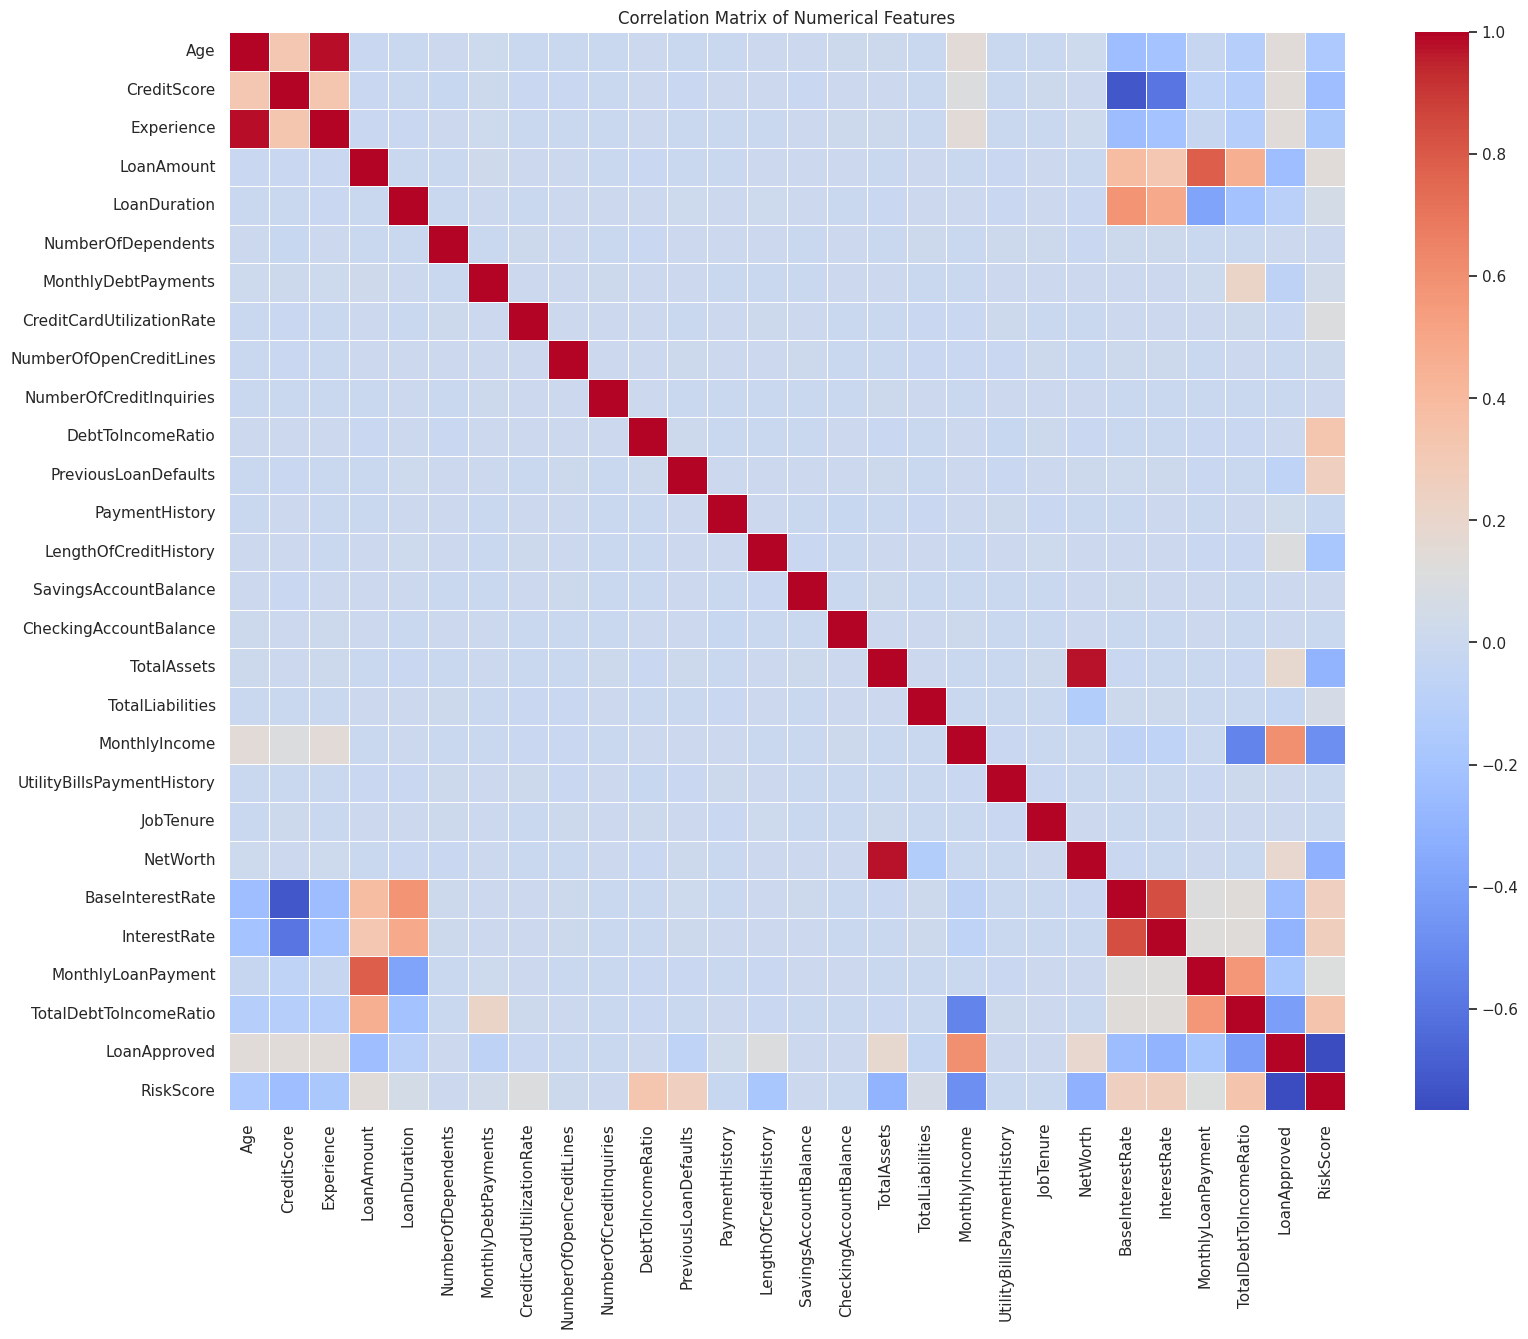

In [ ]:
# Calculate correlations among numerical variables
correlation = df.select_dtypes(include=['int64', 'float64']).corr()

# Display correlations with LoanApproved
approval_correlation = correlation['LoanApproved'].sort_values(
    ascending=False
)

print("Correlation with Loan Approval:")
print(approval_correlation)

# Visualize the correlation matrix
plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.5
)

plt.title('Correlation Matrix of Numerical Features')
plt.show()

### Correlation Analysis Findings

Correlation analysis identified MonthlyIncome (0.604) as the strongest positive correlate of LoanApproved, while RiskScore (-0.766) showed the strongest negative correlation.

Other negatively correlated features include TotalDebtToIncomeRatio (-0.410), InterestRate (-0.302), and LoanAmount (-0.239).

These findings suggest that income, financial risk indicators, debt burden, and loan characteristics are associated with historical approval decisions.

RiskScore will require further investigation to determine whether it introduces target leakage or duplicates information already represented by other variables. Correlation does not imply causation.

In [ ]:
categorical_columns = [
    'EmploymentStatus',
    'EducationLevel',
    'MaritalStatus',
    'HomeOwnershipStatus',
    'LoanPurpose'
]

for column in categorical_columns:
    print(f"\nApproval rate by {column}:")
    print(
        df.groupby(column, dropna=False)['LoanApproved']
        .mean()
        .sort_values(ascending=False)
        .round(3)
    )


Approval rate by EmploymentStatus:
EmploymentStatus
Self-Employed   0.278
Employed        0.240
Unemployed      0.182
Name: LoanApproved, dtype: float64

Approval rate by EducationLevel:
EducationLevel
Doctorate     0.457
Master        0.365
Bachelor      0.278
Associate     0.214
High School   0.153
NaN           0.000
Name: LoanApproved, dtype: float64

Approval rate by MaritalStatus:
MaritalStatus
NaN        0.245
Divorced   0.245
Single     0.240
Married    0.237
Widowed    0.230
Name: LoanApproved, dtype: float64

Approval rate by HomeOwnershipStatus:
HomeOwnershipStatus
Mortgage   0.252
Own        0.249
Rent       0.228
Other      0.205
Name: LoanApproved, dtype: float64

Approval rate by LoanPurpose:
LoanPurpose
Education            0.253
Auto                 0.243
Home                 0.238
Debt Consolidation   0.235
Other                0.223
Name: LoanApproved, dtype: float64


### Categorical Feature Analysis

The categorical analysis revealed differences in historical loan approval rates across applicant groups.

- Self-employed applicants had the highest approval rate (27.8%), while unemployed applicants had the lowest (18.2%).
- Applicants with doctorate and master's qualifications had higher approval rates than applicants with lower education levels.
- Marital status showed relatively little variation in approval rates.
- Homeowners and mortgage holders had slightly higher approval rates than renters.
- Loan purpose showed relatively small differences, with education-related applications having the highest approval rate.

An unusual finding was that applications with missing EducationLevel values had a 0% approval rate. This requires further investigation before preprocessing. Missing values will not automatically be interpreted as evidence of ineligibility.

These are associations in historical decisions and should not be interpreted as evidence that demographic characteristics cause approval outcomes.

In [ ]:
# Examine approval status for records with missing education
missing_education = df[df['EducationLevel'].isnull()]

print("Records with missing education:", len(missing_education))

print("\nApproval distribution:")
print(missing_education['LoanApproved'].value_counts())

print("\nApproval rate:")
print(missing_education['LoanApproved'].mean())

Records with missing education: 901

Approval distribution:
LoanApproved
0    901
Name: count, dtype: int64

Approval rate:
0.0


### Investigation of Missing Education Values

Further investigation revealed that all 901 records with missing EducationLevel values belonged to rejected loan applications.

This indicates a potentially systematic missing-data pattern rather than random missingness. The relationship may reflect the original data collection process or historical approval practices.

The missing values will be retained for investigation and handled through an appropriate preprocessing strategy. Missing education information will not be interpreted as proof of applicant ineligibility.

In [ ]:
# Check approval distribution for missing values in each column

columns_to_check = [
    'MaritalStatus',
    'SavingsAccountBalance'
]

for column in columns_to_check:
    missing_records = df[df[column].isnull()]

    print(f"\n{column}")
    print("Missing records:", len(missing_records))
    print("Approval distribution:")
    print(missing_records['LoanApproved'].value_counts())
    print("Approval rate:", missing_records['LoanApproved'].mean())


MaritalStatus
Missing records: 1331
Approval distribution:
LoanApproved
0    1005
1     326
Name: count, dtype: int64
Approval rate: 0.24492862509391436

SavingsAccountBalance
Missing records: 572
Approval distribution:
LoanApproved
0    421
1    151
Name: count, dtype: int64
Approval rate: 0.263986013986014


### Missing Value Analysis Findings

The investigation identified different patterns across the three columns with missing values.

- EducationLevel: All 901 records with missing values were rejected applications, indicating a potentially systematic missing-data pattern.
- MaritalStatus: The 1,331 records with missing values had an approval rate of 24.5%, close to the overall approval rate.
- SavingsAccountBalance: The 572 records with missing values had an approval rate of 26.4%.

The missing values will be handled using appropriate imputation strategies within the preprocessing pipeline. Missingness indicators will also be considered, particularly for EducationLevel.

The imputation process will be fitted using training data only to prevent data leakage.

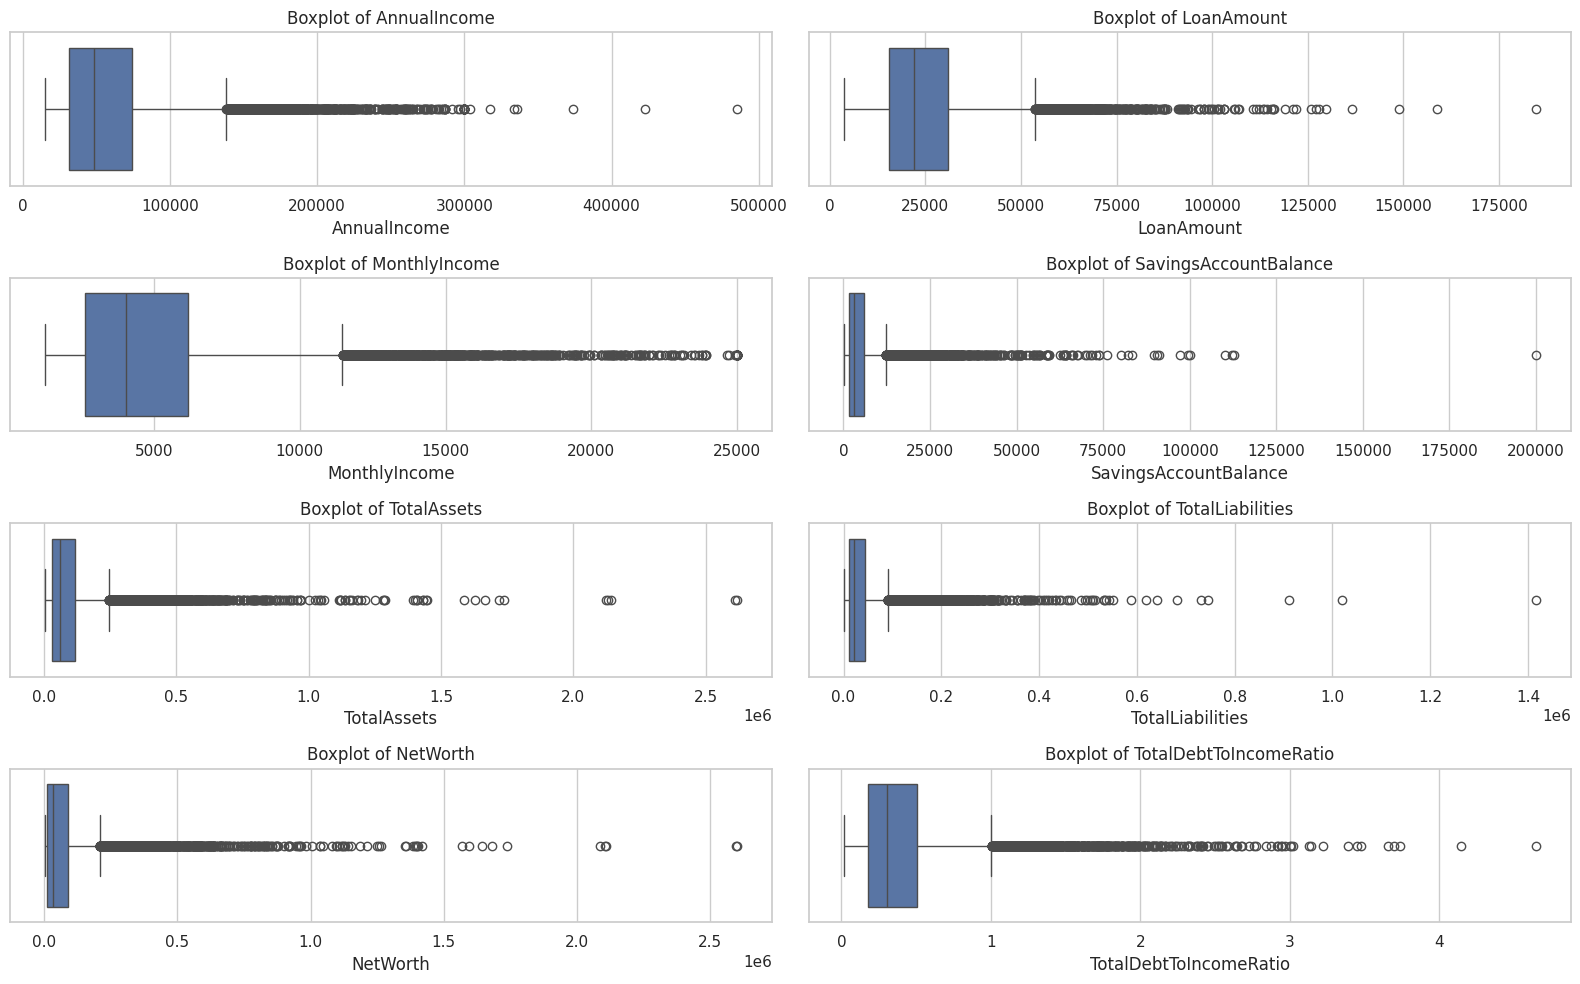

In [ ]:
# Select important financial variables
financial_features = [
    'AnnualIncome',
    'LoanAmount',
    'MonthlyIncome',
    'SavingsAccountBalance',
    'TotalAssets',
    'TotalLiabilities',
    'NetWorth',
    'TotalDebtToIncomeRatio'
]

# Convert AnnualIncome to numeric for analysis
df['AnnualIncome'] = (
    df['AnnualIncome']
    .astype(str)
    .str.replace(r'[$,]', '', regex=True)
    .astype(float)
)

# Plot boxplots
plt.figure(figsize=(16, 10))

for i, column in enumerate(financial_features, 1):
    plt.subplot(4, 2, i)
    sns.boxplot(x=df[column])
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.show()

In [ ]:
# Identify potential outliers using the IQR method

for column in financial_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Lower bound:", round(lower_bound, 2))
    print("Upper bound:", round(upper_bound, 2))
    print("Potential outliers:", len(outliers))


AnnualIncome
Lower bound: -32389.0
Upper bound: 138459.0
Potential outliers: 947

LoanAmount
Lower bound: -7315.0
Upper bound: 53725.0
Potential outliers: 746

MonthlyIncome
Lower bound: -2670.54
Upper bound: 11463.12
Potential outliers: 925

SavingsAccountBalance
Lower bound: -4948.88
Upper bound: 12360.12
Potential outliers: 1547

TotalAssets
Lower bound: -98157.25
Upper bound: 246742.75
Potential outliers: 1442

TotalLiabilities
Lower bound: -36727.88
Upper bound: 91071.12
Potential outliers: 1533

NetWorth
Lower bound: -111401.38
Upper bound: 208961.62
Potential outliers: 1564

TotalDebtToIncomeRatio
Lower bound: -0.31
Upper bound: 1.0
Potential outliers: 1152


### Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential outliers in eight financial variables.

NetWorth recorded the highest number of potential outliers (1,564), followed by SavingsAccountBalance (1,547) and TotalLiabilities (1,533). LoanAmount had the lowest number (746).

These observations indicate that several financial variables have skewed distributions and extreme values.

Outliers will not automatically be removed because they may represent genuine financial differences between applicants. Robust preprocessing techniques and appropriate outlier treatment will be considered during model development.

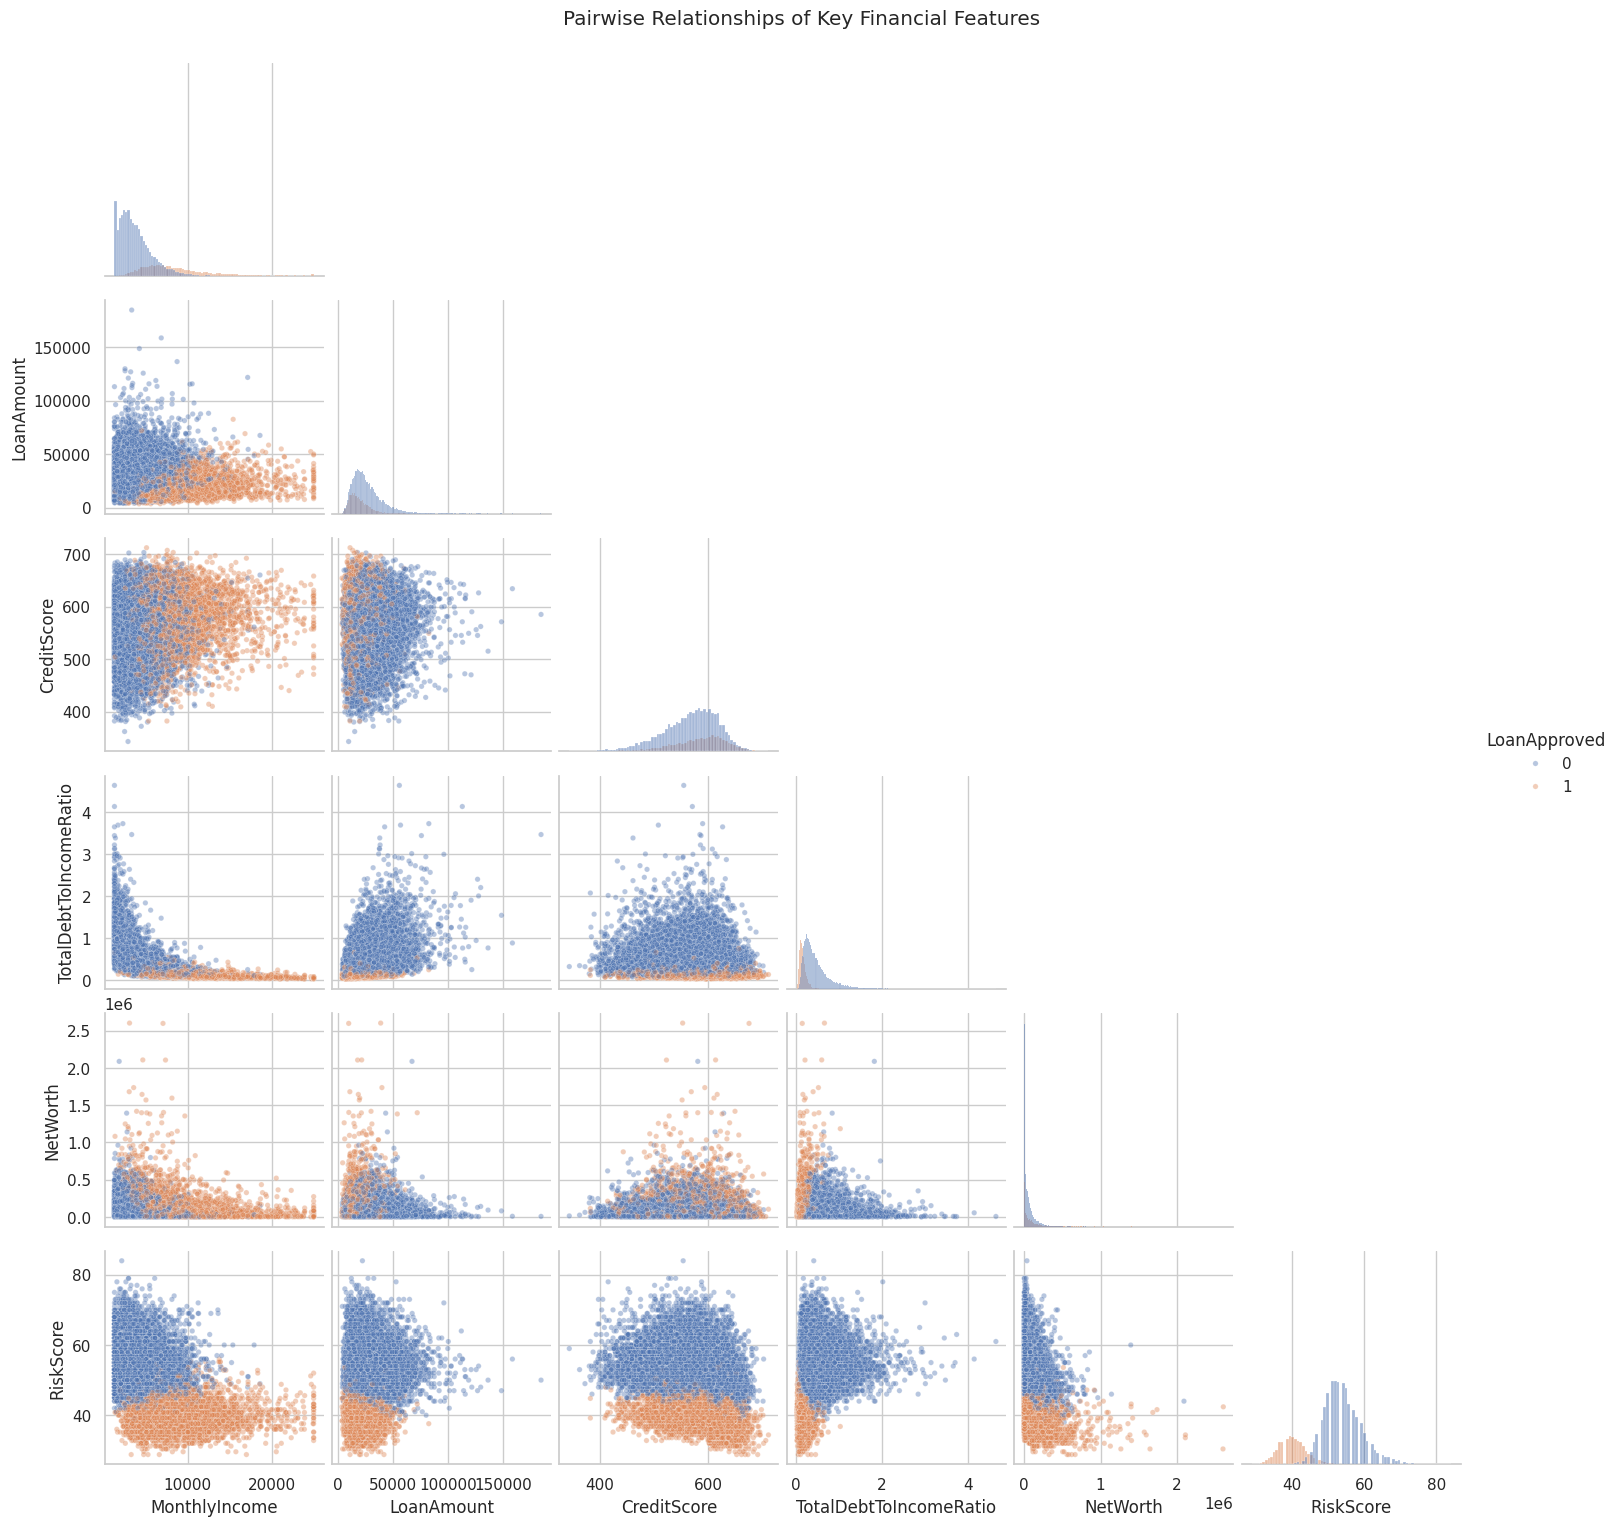

In [ ]:
# Select key financial variables
selected_features = [
    'MonthlyIncome',
    'LoanAmount',
    'CreditScore',
    'TotalDebtToIncomeRatio',
    'NetWorth',
    'RiskScore',
    'LoanApproved'
]

# Create pair plots
sns.pairplot(
    df[selected_features],
    hue='LoanApproved',
    diag_kind='hist',
    corner=True,
    plot_kws={'alpha': 0.4, 's': 15}
)

plt.suptitle(
    'Pairwise Relationships of Key Financial Features',
    y=1.02
)

plt.show()

In [ ]:
from scipy.stats import mannwhitneyu

# Select numerical features for testing
features_to_test = [
    'MonthlyIncome',
    'CreditScore',
    'LoanAmount',
    'NetWorth',
    'RiskScore',
    'TotalDebtToIncomeRatio'
]

for column in features_to_test:

    rejected = df[df['LoanApproved'] == 0][column].dropna()
    approved = df[df['LoanApproved'] == 1][column].dropna()

    statistic, p_value = mannwhitneyu(
        rejected,
        approved,
        alternative='two-sided'
    )

    print(f"\nFeature: {column}")
    print("P-value:", round(p_value, 6))

    if p_value < 0.05:
        print("Result: Statistically significant difference")
    else:
        print("Result: No statistically significant difference")


Feature: MonthlyIncome
P-value: 0.0
Result: Statistically significant difference

Feature: CreditScore
P-value: 0.0
Result: Statistically significant difference

Feature: LoanAmount
P-value: 0.0
Result: Statistically significant difference

Feature: NetWorth
P-value: 0.0
Result: Statistically significant difference

Feature: RiskScore
P-value: 0.0
Result: Statistically significant difference

Feature: TotalDebtToIncomeRatio
P-value: 0.0
Result: Statistically significant difference


### Statistical Significance Testing

The Mann–Whitney U test was conducted to compare numerical feature distributions between approved and rejected loan applications.

All six tested features (MonthlyIncome, CreditScore, LoanAmount, NetWorth, RiskScore and TotalDebtToIncomeRatio) produced p-values below 0.05.

The null hypothesis was therefore rejected for all six features, indicating statistically significant differences between the two approval groups.

These findings suggest that the selected financial variables may contain useful predictive information. However, statistical significance does not establish causation or guarantee strong predictive performance.

In [ ]:
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

p_values = []

for column in features_to_test:
    rejected = df[df['LoanApproved'] == 0][column].dropna()
    approved = df[df['LoanApproved'] == 1][column].dropna()

    _, p_value = mannwhitneyu(
        rejected,
        approved,
        alternative='two-sided'
    )

    p_values.append(p_value)

# Apply Bonferroni correction
reject, corrected_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method='bonferroni'
)

results = pd.DataFrame({
    'Feature': features_to_test,
    'Original_P_Value': p_values,
    'Corrected_P_Value': corrected_p,
    'Significant': reject
})

results

,Feature,Original_P_Value,Corrected_P_Value,Significant
0,MonthlyIncome,0.000,0.000,True
1,CreditScore,0.000,0.000,True
2,LoanAmount,0.000,0.000,True
3,NetWorth,0.000,0.000,True
4,RiskScore,0.000,0.000,True
5,TotalDebtToIncomeRatio,0.000,0.000,True


### Multiple Testing Correction

The Bonferroni correction was applied to the six Mann–Whitney U tests to control the family-wise error rate.

All six features remained statistically significant after correction, with adjusted p-values below 0.05.

This strengthens the evidence that the distributions of these financial variables differ between approved and rejected applications. The findings support further investigation of these features during model development.

In [ ]:
from scipy.stats import chi2_contingency

categorical_features = [
    'EmploymentStatus',
    'EducationLevel',
    'MaritalStatus',
    'HomeOwnershipStatus',
    'LoanPurpose'
]

for column in categorical_features:

    contingency_table = pd.crosstab(
        df[column].fillna('Missing'),
        df['LoanApproved']
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    print(f"\nFeature: {column}")
    print("Chi-square statistic:", round(chi2, 3))
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Result: Significant association")
    else:
        print("Result: No significant association")


Feature: EmploymentStatus
Chi-square statistic: 38.507
P-value: 4.349260610875047e-09
Result: Significant association

Feature: EducationLevel
Chi-square statistic: 1068.928
P-value: 7.157928791252534e-229
Result: Significant association

Feature: MaritalStatus
Chi-square statistic: 1.374
P-value: 0.8487015510335627
Result: No significant association

Feature: HomeOwnershipStatus
Chi-square statistic: 26.329
P-value: 8.138932140772307e-06
Result: Significant association

Feature: LoanPurpose
Chi-square statistic: 6.696
P-value: 0.1528671128648066
Result: No significant association


### Chi-Square Test of Independence

The Chi-square test was used to investigate associations between categorical applicant characteristics and historical loan approval decisions.

The results showed statistically significant associations for:
- EmploymentStatus (p < 0.05)
- EducationLevel (p < 0.05)
- HomeOwnershipStatus (p < 0.05)

MaritalStatus (p = 0.849) and LoanPurpose (p = 0.153) did not show statistically significant associations.

These findings suggest that employment status, education level and home ownership may provide useful information for predicting historical loan approval decisions.

The results indicate association rather than causation. Further analysis is required to assess practical significance and potential fairness concerns.

In [ ]:
from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

chi_p_values = []

for column in categorical_features:

    contingency_table = pd.crosstab(
        df[column].fillna('Missing'),
        df['LoanApproved']
    )

    _, p_value, _, _ = chi2_contingency(contingency_table)

    chi_p_values.append(p_value)

# Apply Bonferroni correction
reject, corrected_p, _, _ = multipletests(
    chi_p_values,
    alpha=0.05,
    method='bonferroni'
)

chi_results = pd.DataFrame({
    'Feature': categorical_features,
    'Original_P_Value': chi_p_values,
    'Corrected_P_Value': corrected_p,
    'Significant': reject
})

chi_results

,Feature,Original_P_Value,Corrected_P_Value,Significant
0,EmploymentStatus,0.000,0.000,True
1,EducationLevel,0.000,0.000,True
2,MaritalStatus,0.849,1.000,False
3,HomeOwnershipStatus,0.000,0.000,True
4,LoanPurpose,0.153,0.764,False


### Chi-Square Tests: Categorical Feature Associations

Chi-square tests of independence were conducted to examine the relationship between categorical applicant characteristics and historical loan approval decisions. Bonferroni correction was applied to account for the five statistical tests performed.

The results showed statistically significant associations between loan approval and **EmploymentStatus, EducationLevel, and HomeOwnershipStatus** (adjusted p-values below 0.05).

However, **MaritalStatus and LoanPurpose** did not show statistically significant associations with loan approval after correction.

These findings suggest that employment status, education level, and home ownership may provide useful information for understanding historical approval patterns. However, statistical significance does not establish causation or guarantee predictive usefulness. The findings should also be interpreted cautiously because missing education values were disproportionately associated with rejected applications, which may reflect historical data collection or decision-making practices.

The results will inform feature assessment during model development, while fairness and potential historical decision-making bias will be considered during evaluation.

In [ ]:
# Inspect remaining categorical columns
categorical_columns = df.select_dtypes(include=['object']).columns.tolist()

print("Categorical columns:")
for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False).head(10))

Categorical columns:

EmploymentStatus
EmploymentStatus
Employed         17036
Self-Employed     1573
Unemployed        1391
Name: count, dtype: int64

EducationLevel
EducationLevel
Bachelor       5804
High School    5592
Associate      3850
Master         2933
Doctorate       920
NaN             901
Name: count, dtype: int64

MaritalStatus
MaritalStatus
Married     9370
Single      5665
Divorced    2704
NaN         1331
Widowed      930
Name: count, dtype: int64

HomeOwnershipStatus
HomeOwnershipStatus
Mortgage    7939
Rent        6087
Own         3938
Other       2036
Name: count, dtype: int64

BankruptcyHistory
BankruptcyHistory
No     18952
Yes     1048
Name: count, dtype: int64

LoanPurpose
LoanPurpose
Home                  5925
Debt Consolidation    5027
Auto                  4034
Education             3008
Other                 2006
Name: count, dtype: int64


In [ ]:
# Review potentially leakage-prone features
potential_leakage_features = [
    'RiskScore',
    'BaseInterestRate',
    'InterestRate',
    'MonthlyLoanPayment'
]

print("Potential leakage feature analysis:")

for column in potential_leakage_features:
    print(f"\n{column}")
    print(df.groupby('LoanApproved')[column].agg(
        ['mean', 'median', 'min', 'max']
    ))

Potential leakage feature analysis:

RiskScore
               mean  median    min    max
LoanApproved                             
0            54.106  54.000 38.000 84.000
1            40.133  40.000 28.800 56.000

BaseInterestRate
              mean  median   min   max
LoanApproved                          
0            0.244   0.241 0.142 0.405
1            0.223   0.221 0.130 0.367

InterestRate
              mean  median   min   max
LoanApproved                          
0            0.246   0.243 0.125 0.447
1            0.216   0.214 0.113 0.383

MonthlyLoanPayment
                mean  median     min       max
LoanApproved                                  
0            981.268 791.221 103.153 10892.630
1            689.799 576.035  97.030  5677.679


### Potential Data Leakage Assessment

Four features were identified for further investigation: RiskScore, BaseInterestRate, InterestRate, and MonthlyLoanPayment.

A comparison of their distributions across approved and rejected applications revealed noticeable differences. RiskScore, in particular, showed a strong relationship with the target variable.

However, the dataset does not provide sufficient documentation to establish whether these variables were available at the time of the original loan application or were generated during subsequent risk assessment, pricing, or approval processes.

To minimise the risk of data leakage and ensure a more realistic prediction scenario, these four features will be excluded from the initial modelling dataset.

This conservative decision helps ensure that the models rely primarily on applicant information that could reasonably be available during an initial loan assessment.

In [ ]:
# Define target variable
target = 'LoanApproved'

# Features excluded due to potential data leakage
excluded_features = [
    'RiskScore',
    'BaseInterestRate',
    'InterestRate',
    'MonthlyLoanPayment'
]

# Separate predictors and target
X = df.drop(columns=[target] + excluded_features)
y = df[target]

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Predictor dataset shape:", X.shape)
print("Target dataset shape:", y.shape)
print("\nNumerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nRemaining missing values:")
print(X.isnull().sum()[X.isnull().sum() > 0])

Predictor dataset shape: (20000, 30)
Target dataset shape: (20000,)

Numerical features: 24
Categorical features: 6

Remaining missing values:
EducationLevel            901
MaritalStatus            1331
SavingsAccountBalance     572
dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (16000, 30)
Testing features: (4000, 30)

Training target distribution:
LoanApproved
0   76.100
1   23.900
Name: proportion, dtype: float64

Testing target distribution:
LoanApproved
0   76.100
1   23.900
Name: proportion, dtype: float64


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Numerical preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Unknown'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
# Fit preprocessing on training data and transform it
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nAny missing values in processed training data?",
      np.isnan(X_train_processed.toarray() if hasattr(
          X_train_processed, "toarray"
      ) else X_train_processed).any())

Original training shape: (16000, 30)
Processed training shape: (16000, 49)

Original testing shape: (4000, 30)
Processed testing shape: (4000, 49)

Any missing values in processed training data? False


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

# Create baseline model
baseline_model = DummyClassifier(strategy='most_frequent')

# Train the baseline model
baseline_model.fit(X_train_processed, y_train)

# Make predictions
baseline_predictions = baseline_model.predict(X_test_processed)

# Evaluate baseline
baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Accuracy:", round(baseline_accuracy, 4))

print("\nBaseline Classification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    zero_division=0
))

Baseline Accuracy: 0.761

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.76      1.00      0.86      3044
           1       0.00      0.00      0.00       956

    accuracy                           0.76      4000
   macro avg       0.38      0.50      0.43      4000
weighted avg       0.58      0.76      0.66      4000



### Baseline Model Evaluation

A DummyClassifier using the most frequent class strategy was established as the baseline model.

The model achieved an accuracy of 76.1%, reflecting the proportion of rejected applications in the dataset. However, it recorded zero precision, recall, and F1-score for approved applications.

This demonstrates that a high accuracy score does not necessarily indicate effective classification, particularly when the target variable is imbalanced.

The baseline model fails to identify any approved applications and therefore provides no useful discrimination for the minority class.

Consequently, subsequent models will be evaluated using additional metrics, including precision, recall, F1-score, balanced accuracy, and ROC-AUC, with particular attention to their ability to identify approved applications.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the model
logistic_model.fit(X_train, y_train)

# Generate predictions
logistic_predictions = logistic_model.predict(X_test)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    classification_report
)

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(y_test, logistic_predictions)
logistic_precision = precision_score(y_test, logistic_predictions)
logistic_recall = recall_score(y_test, logistic_predictions)
logistic_f1 = f1_score(y_test, logistic_predictions)
logistic_auc = roc_auc_score(
    y_test,
    logistic_model.predict_proba(X_test)[:, 1]
)
logistic_balanced_accuracy = balanced_accuracy_score(
    y_test,
    logistic_predictions
)

# Display results
print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")
print("Accuracy:", round(logistic_accuracy, 4))
print("Precision:", round(logistic_precision, 4))
print("Recall:", round(logistic_recall, 4))
print("F1-score:", round(logistic_f1, 4))
print("ROC-AUC:", round(logistic_auc, 4))
print("Balanced Accuracy:", round(logistic_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, logistic_predictions))

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 0.9337
Precision: 0.8751
Recall: 0.8431
F1-score: 0.8588
ROC-AUC: 0.9798
Balanced Accuracy: 0.9027

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      3044
           1       0.88      0.84      0.86       956

    accuracy                           0.93      4000
   macro avg       0.91      0.90      0.91      4000
weighted avg       0.93      0.93      0.93      4000



### Logistic Regression Model Evaluation

The Logistic Regression model achieved an accuracy of 93.37%, significantly outperforming the baseline model's accuracy of 76.10%.

For the approved class (class 1), the model recorded a precision of 87.51%, recall of 84.31%, and F1-score of 85.88%. Its ROC-AUC score was 0.9798, indicating excellent discrimination between historical approval and rejection decisions.

The balanced accuracy of 90.27% also demonstrates that the model performs well across both target classes, rather than relying primarily on the majority class.

These results establish Logistic Regression as a strong initial predictive model. However, the target represents historical loan approval decisions rather than actual loan repayment or default outcomes. Therefore, these metrics measure how well the model reproduces historical approval patterns, not its ability to identify creditworthy borrowers or predict defaults.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree pipeline
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        max_depth=10,
        min_samples_split=10
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

# Generate predictions
decision_tree_predictions = decision_tree_model.predict(X_test)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [ ]:
# Generate evaluation metrics
dt_accuracy = accuracy_score(y_test, decision_tree_predictions)
dt_precision = precision_score(y_test, decision_tree_predictions)
dt_recall = recall_score(y_test, decision_tree_predictions)
dt_f1 = f1_score(y_test, decision_tree_predictions)

dt_auc = roc_auc_score(
    y_test,
    decision_tree_model.predict_proba(X_test)[:, 1]
)

dt_balanced_accuracy = balanced_accuracy_score(
    y_test,
    decision_tree_predictions
)

print("DECISION TREE PERFORMANCE")
print("--------------------------")
print("Accuracy:", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall:", round(dt_recall, 4))
print("F1-score:", round(dt_f1, 4))
print("ROC-AUC:", round(dt_auc, 4))
print("Balanced Accuracy:", round(dt_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, decision_tree_predictions))

DECISION TREE PERFORMANCE
--------------------------
Accuracy: 0.8878
Precision: 0.7931
Recall: 0.7176
F1-score: 0.7534
ROC-AUC: 0.9113
Balanced Accuracy: 0.8294

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.94      0.93      3044
           1       0.79      0.72      0.75       956

    accuracy                           0.89      4000
   macro avg       0.85      0.83      0.84      4000
weighted avg       0.89      0.89      0.89      4000



### Decision Tree Model Evaluation

The Decision Tree classifier achieved an accuracy of 88.78%, precision of 79.31%, recall of 71.76%, and F1-score of 75.34% for the approved class.

Its ROC-AUC was 0.9113, while balanced accuracy was 82.94%.

Although the Decision Tree demonstrated good classification performance, it underperformed compared with Logistic Regression across all evaluated metrics. In particular, its lower recall indicates that it correctly identifies fewer historically approved applications.

This suggests that, with the current hyperparameter configuration, Logistic Regression provides better predictive performance. Further experimentation with ensemble models and hyperparameter optimisation will help establish whether more complex algorithms can improve these results.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

# Generate predictions
random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [ ]:
# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, random_forest_predictions)
rf_precision = precision_score(y_test, random_forest_predictions)
rf_recall = recall_score(y_test, random_forest_predictions)
rf_f1 = f1_score(y_test, random_forest_predictions)

rf_auc = roc_auc_score(
    y_test,
    random_forest_model.predict_proba(X_test)[:, 1]
)

rf_balanced_accuracy = balanced_accuracy_score(
    y_test,
    random_forest_predictions
)

print("RANDOM FOREST PERFORMANCE")
print("--------------------------")
print("Accuracy:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1-score:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_auc, 4))
print("Balanced Accuracy:", round(rf_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, random_forest_predictions))

RANDOM FOREST PERFORMANCE
--------------------------
Accuracy: 0.9185
Precision: 0.8732
Recall: 0.7709
F1-score: 0.8189
ROC-AUC: 0.9661
Balanced Accuracy: 0.8679

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.96      0.95      3044
           1       0.87      0.77      0.82       956

    accuracy                           0.92      4000
   macro avg       0.90      0.87      0.88      4000
weighted avg       0.92      0.92      0.92      4000



In [ ]:
from sklearn.ensemble import ExtraTreesClassifier

# Create Extra Trees pipeline
extra_trees_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Train the model
extra_trees_model.fit(X_train, y_train)

# Generate predictions
extra_trees_predictions = extra_trees_model.predict(X_test)

print("Extra Trees model trained successfully.")

Extra Trees model trained successfully.


In [ ]:
# Calculate evaluation metrics
et_accuracy = accuracy_score(y_test, extra_trees_predictions)
et_precision = precision_score(y_test, extra_trees_predictions)
et_recall = recall_score(y_test, extra_trees_predictions)
et_f1 = f1_score(y_test, extra_trees_predictions)

et_auc = roc_auc_score(
    y_test,
    extra_trees_model.predict_proba(X_test)[:, 1]
)

et_balanced_accuracy = balanced_accuracy_score(
    y_test,
    extra_trees_predictions
)

print("EXTRA TREES PERFORMANCE")
print("------------------------")
print("Accuracy:", round(et_accuracy, 4))
print("Precision:", round(et_precision, 4))
print("Recall:", round(et_recall, 4))
print("F1-score:", round(et_f1, 4))
print("ROC-AUC:", round(et_auc, 4))
print("Balanced Accuracy:", round(et_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, extra_trees_predictions))

EXTRA TREES PERFORMANCE
------------------------
Accuracy: 0.8905
Precision: 0.9137
Recall: 0.5983
F1-score: 0.7231
ROC-AUC: 0.964
Balanced Accuracy: 0.7903

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.93      3044
           1       0.91      0.60      0.72       956

    accuracy                           0.89      4000
   macro avg       0.90      0.79      0.83      4000
weighted avg       0.89      0.89      0.88      4000



### Extra Trees Model Evaluation

The Extra Trees classifier achieved an accuracy of 89.05%, precision of 91.37%, recall of 59.83%, and F1-score of 72.31% for the approved class.

Its ROC-AUC was 0.9640, while balanced accuracy was 79.03%.

The model recorded the highest precision among the models evaluated so far. However, its recall was considerably lower, indicating that it failed to identify approximately 40% of historically approved applications.

The relatively high ROC-AUC suggests that the model has strong ranking ability, although its default classification threshold produces a less favourable precision-recall balance.

These results demonstrate the importance of evaluating multiple metrics rather than selecting a model based on precision or accuracy alone.

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create Gradient Boosting pipeline
gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

# Generate predictions
gradient_boosting_predictions = gradient_boosting_model.predict(X_test)

print("Gradient Boosting model trained successfully.")

Gradient Boosting model trained successfully.


In [ ]:
# Calculate evaluation metrics
gb_accuracy = accuracy_score(y_test, gradient_boosting_predictions)
gb_precision = precision_score(y_test, gradient_boosting_predictions)
gb_recall = recall_score(y_test, gradient_boosting_predictions)
gb_f1 = f1_score(y_test, gradient_boosting_predictions)

gb_auc = roc_auc_score(
    y_test,
    gradient_boosting_model.predict_proba(X_test)[:, 1]
)

gb_balanced_accuracy = balanced_accuracy_score(
    y_test,
    gradient_boosting_predictions
)

print("GRADIENT BOOSTING PERFORMANCE")
print("-----------------------------")
print("Accuracy:", round(gb_accuracy, 4))
print("Precision:", round(gb_precision, 4))
print("Recall:", round(gb_recall, 4))
print("F1-score:", round(gb_f1, 4))
print("ROC-AUC:", round(gb_auc, 4))
print("Balanced Accuracy:", round(gb_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, gradient_boosting_predictions))

GRADIENT BOOSTING PERFORMANCE
-----------------------------
Accuracy: 0.9293
Precision: 0.876
Recall: 0.8201
F1-score: 0.8471
ROC-AUC: 0.9752
Balanced Accuracy: 0.8918

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      3044
           1       0.88      0.82      0.85       956

    accuracy                           0.93      4000
   macro avg       0.91      0.89      0.90      4000
weighted avg       0.93      0.93      0.93      4000



### Gradient Boosting Model Evaluation

The Gradient Boosting classifier achieved an accuracy of 92.93%, precision of 87.60%, recall of 82.01%, and F1-score of 84.71% for the approved class.

The model recorded a ROC-AUC of 0.9752 and balanced accuracy of 89.18%.

Gradient Boosting demonstrated strong classification performance and outperformed the individual Decision Tree and Random Forest in several evaluation metrics.

However, Logistic Regression remained slightly better overall, particularly in accuracy, recall, F1-score, ROC-AUC, and balanced accuracy. Gradient Boosting achieved marginally higher precision.

These results demonstrate that both algorithms are competitive, although Logistic Regression currently offers the strongest overall balance of predictive performance.

In [ ]:
from sklearn.svm import SVC

# Create SVM pipeline
svm_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(
        kernel='rbf',
        C=1.0,
        probability=True,
        random_state=42
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Generate predictions
svm_predictions = svm_model.predict(X_test)

print("Support Vector Machine model trained successfully.")

Support Vector Machine model trained successfully.


In [ ]:
# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, svm_predictions)
svm_precision = precision_score(y_test, svm_predictions)
svm_recall = recall_score(y_test, svm_predictions)
svm_f1 = f1_score(y_test, svm_predictions)

svm_auc = roc_auc_score(
    y_test,
    svm_model.predict_proba(X_test)[:, 1]
)

svm_balanced_accuracy = balanced_accuracy_score(
    y_test,
    svm_predictions
)

print("SUPPORT VECTOR MACHINE PERFORMANCE")
print("----------------------------------")
print("Accuracy:", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall:", round(svm_recall, 4))
print("F1-score:", round(svm_f1, 4))
print("ROC-AUC:", round(svm_auc, 4))
print("Balanced Accuracy:", round(svm_balanced_accuracy, 4))

print("\nClassification Report:")
print(classification_report(y_test, svm_predictions))

SUPPORT VECTOR MACHINE PERFORMANCE
----------------------------------
Accuracy: 0.9267
Precision: 0.8687
Recall: 0.8169
F1-score: 0.842
ROC-AUC: 0.9762
Balanced Accuracy: 0.8891

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.96      0.95      3044
           1       0.87      0.82      0.84       956

    accuracy                           0.93      4000
   macro avg       0.91      0.89      0.90      4000
weighted avg       0.93      0.93      0.93      4000



### Support Vector Machine Model Evaluation

The Support Vector Machine classifier achieved an accuracy of 92.67%, precision of 86.87%, recall of 81.69%, and F1-score of 84.20% for the approved class.

Its ROC-AUC was 0.9762, while balanced accuracy was 88.91%.

The model demonstrated strong classification performance and good discrimination between the two historical approval classes. However, Logistic Regression achieved better overall results, particularly in accuracy, recall, F1-score, ROC-AUC, and balanced accuracy.

SVM remains a competitive alternative, although its performance does not currently justify selecting it over Logistic Regression.

In [ ]:
# Create a comparison table for all six models
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'Random Forest',
        'Extra Trees',
        'Gradient Boosting',
        'SVM'
    ],
    'Accuracy': [
        logistic_accuracy,
        dt_accuracy,
        rf_accuracy,
        et_accuracy,
        gb_accuracy,
        svm_accuracy
    ],
    'Precision': [
        logistic_precision,
        dt_precision,
        rf_precision,
        et_precision,
        gb_precision,
        svm_precision
    ],
    'Recall': [
        logistic_recall,
        dt_recall,
        rf_recall,
        et_recall,
        gb_recall,
        svm_recall
    ],
    'F1_Score': [
        logistic_f1,
        dt_f1,
        rf_f1,
        et_f1,
        gb_f1,
        svm_f1
    ],
    'ROC_AUC': [
        logistic_auc,
        dt_auc,
        rf_auc,
        et_auc,
        gb_auc,
        svm_auc
    ],
    'Balanced_Accuracy': [
        logistic_balanced_accuracy,
        dt_balanced_accuracy,
        rf_balanced_accuracy,
        et_balanced_accuracy,
        gb_balanced_accuracy,
        svm_balanced_accuracy
    ]
})

model_comparison = model_comparison.sort_values(
    by='F1_Score',
    ascending=False
).reset_index(drop=True)

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Balanced_Accuracy
0,Logistic Regression,0.934,0.875,0.843,0.859,0.980,0.903
1,Gradient Boosting,0.929,0.876,0.820,0.847,0.975,0.892
2,SVM,0.927,0.869,0.817,0.842,0.976,0.889
3,Random Forest,0.918,0.873,0.771,0.819,0.966,0.868
4,Decision Tree,0.888,0.793,0.718,0.753,0.911,0.829
5,Extra Trees,0.890,0.914,0.598,0.723,0.964,0.790


### Comparative Model Selection

Six classification algorithms were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and balanced accuracy.

Logistic Regression emerged as the strongest initial candidate, achieving 93.37% accuracy, 85.88% F1-score, and 97.98% ROC-AUC.

Gradient Boosting and SVM also demonstrated competitive performance. Extra Trees recorded the highest precision at 91.37%, but its lower recall of 59.83% made it less attractive where identifying the positive class is important.

Based on the overall metric comparison, Logistic Regression is selected as the leading candidate for further validation and hyperparameter optimisation. The final selection will consider cross-validation results, model stability, interpretability, and the project's business requirements.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define the six models
models = {
    'Logistic Regression': logistic_model,
    'Decision Tree': decision_tree_model,
    'Random Forest': random_forest_model,
    'Extra Trees': extra_trees_model,
    'Gradient Boosting': gradient_boosting_model,
    'SVM': svm_model
}

# Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'balanced_accuracy': 'balanced_accuracy'
}

# Store cross-validation results
cv_results = []

for name, model in models.items():
    print(f"Evaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results.append({
        'Model': name,
        'Accuracy': scores['test_accuracy'].mean(),
        'Precision': scores['test_precision'].mean(),
        'Recall': scores['test_recall'].mean(),
        'F1_Score': scores['test_f1'].mean(),
        'ROC_AUC': scores['test_roc_auc'].mean(),
        'Balanced_Accuracy': scores['test_balanced_accuracy'].mean()
    })

# Display results
cv_comparison = pd.DataFrame(cv_results)

cv_comparison.sort_values(
    by='F1_Score',
    ascending=False
).round(4)

Evaluating Logistic Regression...
Evaluating Decision Tree...
Evaluating Random Forest...
Evaluating Extra Trees...
Evaluating Gradient Boosting...
Evaluating SVM...


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Balanced_Accuracy
0,Logistic Regression,0.932,0.870,0.843,0.856,0.981,0.901
5,SVM,0.926,0.869,0.814,0.841,0.975,0.888
4,Gradient Boosting,0.924,0.864,0.810,0.836,0.974,0.885
2,Random Forest,0.911,0.854,0.758,0.803,0.964,0.859
1,Decision Tree,0.880,0.759,0.730,0.745,0.890,0.829
3,Extra Trees,0.894,0.911,0.615,0.734,0.962,0.798


In [ ]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter values to test
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced']
}

# Set up GridSearchCV using 5-fold stratified cross-validation
grid_search = GridSearchCV(
    estimator=logistic_model,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit the model using training data only
grid_search.fit(X_train, y_train)

# Display the best parameters and score
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 10, 'classifier__class_weight': None}
Best Cross-Validation F1 Score: 0.8562


FINAL MODEL PERFORMANCE
------------------------
Accuracy: 0.9335
Precision: 0.8718
Recall: 0.8462
F1 Score: 0.8588
ROC-AUC: 0.9799
Balanced Accuracy: 0.9036

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.95      0.96      0.96      3044
           1       0.87      0.85      0.86       956

    accuracy                           0.93      4000
   macro avg       0.91      0.90      0.91      4000
weighted avg       0.93      0.93      0.93      4000



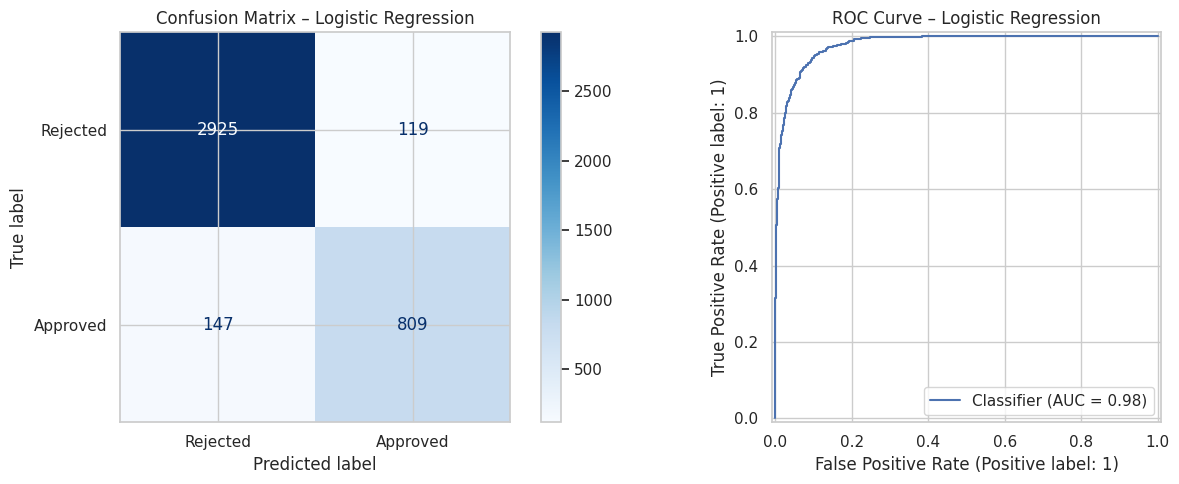

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
import matplotlib.pyplot as plt

# Retrieve the best tuned model
best_model = grid_search.best_estimator_

# Generate predictions
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("FINAL MODEL PERFORMANCE")
print("------------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1 Score:", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_test, y_pred), 4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred))

# Plot confusion matrix and ROC curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Rejected', 'Approved'],
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Confusion Matrix – Logistic Regression')

RocCurveDisplay.from_predictions(
    y_test, y_prob,
    ax=axes[1]
)
axes[1].set_title('ROC Curve – Logistic Regression')

plt.tight_layout()
plt.show()

Performance Analysis Across Customer Segments

In [55]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Combine test data, actual outcomes and model predictions
segment_data = X_test.copy()
segment_data['Actual'] = y_test
segment_data['Predicted'] = y_pred

# Analyse performance across selected customer segments
segments = [
    'EmploymentStatus',
    'EducationLevel',
    'HomeOwnershipStatus'
]

for segment in segments:
    print(f"\nPERFORMANCE BY {segment.upper()}")

    temp = segment_data.copy()
    temp[segment] = temp[segment].fillna('Missing').astype(str)

    results = []

    for group, data in temp.groupby(segment):
        results.append({
            'Segment': group,
            'Records': len(data),
            'Actual_Approval_Rate': round(data['Actual'].mean(), 3),
            'Accuracy': round(
                accuracy_score(data['Actual'], data['Predicted']), 3
            ),
            'Precision': round(
                precision_score(data['Actual'], data['Predicted'], zero_division=0), 3
            ),
            'Recall': round(
                recall_score(data['Actual'], data['Predicted'], zero_division=0), 3
            ),
            'F1_Score': round(
                f1_score(data['Actual'], data['Predicted'], zero_division=0), 3
            )
        })

    segment_results = pd.DataFrame(results)
    display(segment_results.sort_values('Records', ascending=False))


PERFORMANCE BY EMPLOYMENTSTATUS


,Segment,Records,Actual_Approval_Rate,Accuracy,Precision,Recall,F1_Score
0,Employed,3402,0.242,0.936,0.877,0.856,0.866
1,Self-Employed,311,0.264,0.900,0.840,0.768,0.803
2,Unemployed,287,0.174,0.941,0.837,0.820,0.828



PERFORMANCE BY EDUCATIONLEVEL


,Segment,Records,Actual_Approval_Rate,Accuracy,Precision,Recall,F1_Score
1,Bachelor,1163,0.279,0.930,0.877,0.874,0.875
3,High School,1086,0.153,0.959,0.895,0.825,0.859
0,Associate,782,0.207,0.913,0.809,0.759,0.783
4,Master,620,0.377,0.906,0.883,0.868,0.875
5,Missing,193,0.000,1.000,0.000,0.000,0.000
2,Doctorate,156,0.442,0.910,0.899,0.899,0.899



PERFORMANCE BY HOMEOWNERSHIPSTATUS


,Segment,Records,Actual_Approval_Rate,Accuracy,Precision,Recall,F1_Score
0,Mortgage,1624,0.249,0.924,0.858,0.835,0.846
3,Rent,1175,0.231,0.940,0.885,0.849,0.866
2,Own,786,0.265,0.943,0.905,0.875,0.890
1,Other,415,0.173,0.935,0.808,0.819,0.814


### Customer Segment Analysis and Potential Biases

The segment-level evaluation revealed variations in model performance across employment status, education level and home ownership status.

Self-employed applicants recorded the lowest F1-score (0.803) among employment groups, while applicants with associate-level education recorded the lowest F1-score (0.783) among groups with recorded education information. Applicants with missing education information achieved 100% accuracy because all 193 records were historically rejected. However, the model recorded zero recall for the approved class in this group.

Applicants who own their homes achieved the strongest performance among home ownership groups, with an F1-score of 0.890, while the "Other" category recorded the lowest at 0.814.

These differences indicate that model performance is not uniform across all customer segments. The historical rejection of every applicant with missing education information also raises concerns about potential bias in the original approval process.

**Recommendations:**
- Investigate why education information is missing and whether this reflects differences in application processing.
- Monitor model performance across customer segments.
- Review false rejection patterns, particularly among self-employed applicants and applicants with associate-level education.
- Conduct further fairness assessments using appropriate demographic and protected-group information where legally and ethically permissible.

These findings indicate potential disparities but do not independently establish discrimination or prove that the model is biased.

,Feature,Importance,Std_Dev
29,TotalDebtToIncomeRatio,0.281,0.012
25,MonthlyIncome,0.212,0.005
7,LoanDuration,0.068,0.007
28,NetWorth,0.063,0.006
6,LoanAmount,0.061,0.007
4,EducationLevel,0.043,0.003
20,LengthOfCreditHistory,0.035,0.004
16,BankruptcyHistory,0.020,0.002
18,PreviousLoanDefaults,0.014,0.003
10,HomeOwnershipStatus,0.006,0.003


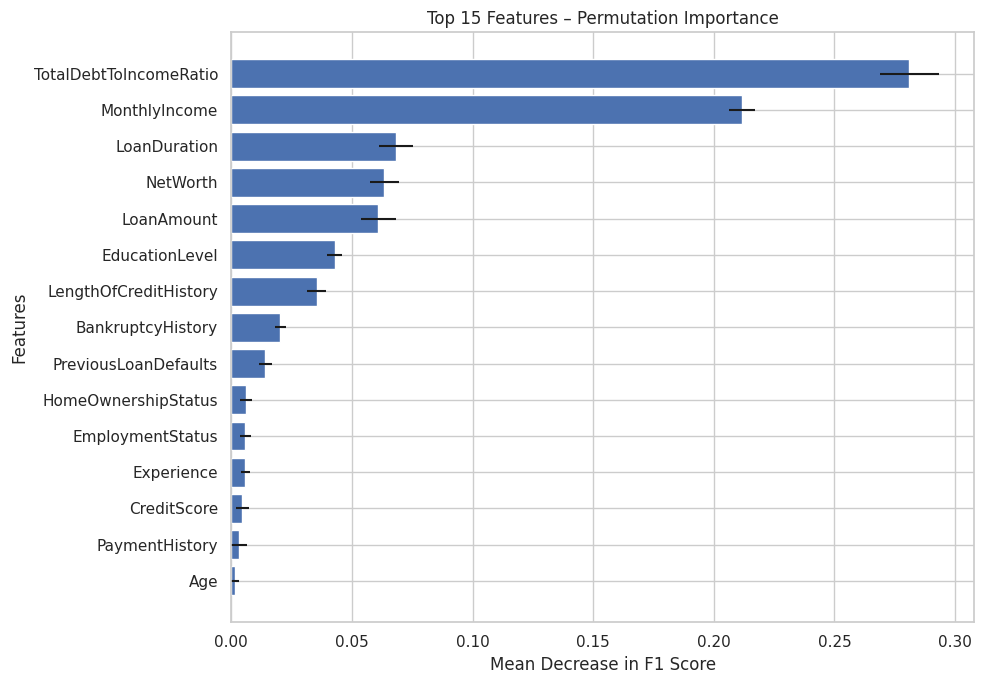

In [56]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Calculate permutation importance
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring='f1',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create feature importance table
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean,
    'Std_Dev': importance.importances_std
})

importance_df = importance_df.sort_values(
    by='Importance', ascending=False
)

# Display the top 15 features
display(importance_df.head(15).round(4))

# Visualise the top 15 features
top_features = importance_df.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features['Feature'],
    top_features['Importance'],
    xerr=top_features['Std_Dev']
)
plt.xlabel('Mean Decrease in F1 Score')
plt.ylabel('Features')
plt.title('Top 15 Features – Permutation Importance')
plt.tight_layout()
plt.show()

### Feature Importance Interpretation

The analysis identifies **TotalDebtToIncomeRatio (0.281)** and **MonthlyIncome (0.212)** as the most influential features in predicting historical loan approval decisions. Other important variables include LoanDuration, NetWorth, LoanAmount and EducationLevel.

These findings indicate that financial capacity and existing debt obligations play a significant role in the model's predictions. Financial institutions should therefore strengthen affordability assessments by considering income stability, debt levels and loan amounts.

However, feature importance indicates predictive influence, not causation. The findings should also be validated against actual loan repayment and default data before informing lending policies.

### Business Recommendations and Implementation Strategy

Based on the model evaluation and feature importance findings, the following recommendations are proposed:

1. **Strengthen affordability assessments:** Give appropriate attention to debt-to-income ratio, monthly income and existing financial obligations when assessing applications.
2. **Improve data quality:** Investigate missing applicant information, particularly education details, to reduce potential bias in historical approval decisions.
3. **Adopt human oversight:** Use model predictions as decision-support tools rather than allowing fully automated loan approval or rejection.
4. **Monitor model performance:** Regularly evaluate accuracy, precision, recall and performance across different customer segments.
5. **Improve data integration:** Incorporate verified repayment histories and default records to support future credit-risk modelling.

**Implementation Approach:** The model should initially be deployed in a controlled pilot environment, with loan officers reviewing its predictions. Full implementation should only be considered after validation using actual repayment outcomes, fairness assessments and stakeholder approval.

### Model Limitations

1. **Target variable limitation:** The dataset predicts historical loan approval decisions rather than actual loan repayment or default outcomes.
2. **Missing data:** Missing education and financial information may affect prediction reliability and introduce potential bias.
3. **Historical bias:** The model may reproduce patterns and biases present in previous lending decisions.
4. **Feature limitations:** Some potentially important variables may be unavailable, while the timing of certain financial indicators is not documented.
5. **Test-set reuse:** The test data was used during initial model comparison, which may introduce some selection bias into the final evaluation.

### Potential Improvements

1. Incorporate actual loan repayment and default records to develop a more reliable credit-risk model.
2. Improve data collection and validation to minimise missing values.
3. Explore additional features such as savings behaviour, employment stability and verified credit history.
4. Apply SHAP analysis to improve model explainability.
5. Conduct regular model retraining, fairness assessments and performance monitoring.
6. Explore cost-sensitive learning and decision-threshold optimisation using validated repayment outcomes.

## Executive Summary for business stakeholders

This project developed a machine learning classification model for FinTech Innovations to predict historical loan approval decisions. Using a dataset of 20,000 loan applications, six classification algorithms were developed and evaluated.

Logistic Regression emerged as the best-performing model following five-fold cross-validation and hyperparameter tuning. The final model achieved **93.35% accuracy, 85.88% F1-score and 97.99% ROC-AUC** on the test dataset.

Feature importance analysis identified TotalDebtToIncomeRatio and MonthlyIncome as the most influential predictors. Segment analysis also revealed variations in performance across employment, education and home ownership categories, highlighting the importance of monitoring potential bias.

The project recommends using the model initially as a decision-support tool, supported by human oversight and continuous performance monitoring. However, since the target represents historical approval decisions rather than actual loan repayment outcomes, further validation using repayment and default data is necessary before deploying it as a credit-risk assessment solution.

## Conclusion

The project successfully developed and evaluated a machine learning model for predicting historical loan approval decisions. Logistic Regression demonstrated the strongest overall performance, achieving 93.35% accuracy and an F1-score of 85.88%.

The analysis highlighted the importance of financial indicators, particularly debt-to-income ratio and monthly income, while also identifying differences in model performance across customer segments.

Although the results demonstrate strong predictive performance, the model's effectiveness in assessing actual creditworthiness remains unverified because repayment and default outcomes were not available. Future improvements should focus on incorporating repayment data, strengthening data quality, addressing potential bias and implementing continuous model monitoring.

Overall, the project provides a foundation for data-driven lending decision support, subject to further validation and responsible implementation.